# Ejercicios Prácticos
## Ejercicio 2

**Objetivo:** Analizar la relación lineal $Y = \texttt{Ozone}$ en función de $X = \texttt{Solar.R}$. Para ello resuelve:

### Preparación de los datos
**Objetivo:** Analizar la relación lineal $Y = \texttt{Ozone}$ en función de $X = \texttt{Solar.R}$.

**Instrucción:** Antes de ajustar, elimine las observaciones con valores faltantes (`NA`) en `Ozone` o `Solar.R`.

**Solución:**

**Importación de Librerias**

In [1]:
import statsmodels.api as sm
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.formula.api as smf

##### Lectura de datos

In [2]:
df = sm.datasets.get_rdataset("airquality", "datasets").data

In [18]:
df

,Ozone,Solar.R,Wind,Temp,Month,Day
0,41.0,190.0,7.4,67,5,1
1,36.0,118.0,8.0,72,5,2
2,12.0,149.0,12.6,74,5,3
3,18.0,313.0,11.5,62,5,4
4,NaN,NaN,14.3,56,5,5
...,...,...,...,...,...,...
148,30.0,193.0,6.9,70,9,26
149,NaN,145.0,13.2,77,9,27
150,14.0,191.0,14.3,75,9,28
151,18.0,131.0,8.0,76,9,29


Primero que nada veamos si realmente hay observaciones donde el campo *Ozone* ó *Solar.R* son Na

In [17]:
values_na = df[(df["Ozone"].isna()) | (df["Solar.R"].isna())]
num_observations_with_na = len(values_na)
print(f"Con el análisis de arriba podemos ver que hay {num_observations_with_na} observaciones que cuentan con NA en la columna Ozone ó Solar.R")

Con el análisis de arriba podemos ver que hay 42 observaciones que cuentan con NA en la columna Ozone ó Solar.R


Vamos a crear un dataframe limpio donde quitamos esas observaciones y lo vamos a llamar **clean_df** donde se cuentan con 111 observaciones

In [19]:
clean_df = df.dropna(subset=['Solar.R', 'Ozone'])

In [20]:
clean_df

,Ozone,Solar.R,Wind,Temp,Month,Day
0,41.0,190.0,7.4,67,5,1
1,36.0,118.0,8.0,72,5,2
2,12.0,149.0,12.6,74,5,3
3,18.0,313.0,11.5,62,5,4
6,23.0,299.0,8.6,65,5,7
...,...,...,...,...,...,...
147,14.0,20.0,16.6,63,9,25
148,30.0,193.0,6.9,70,9,26
150,14.0,191.0,14.3,75,9,28
151,18.0,131.0,8.0,76,9,29


### 1. Estimación de parámetros
**Instrucción:** Calcula la estimación de $\beta_0$, $\beta_1$ y $\sigma^2$.

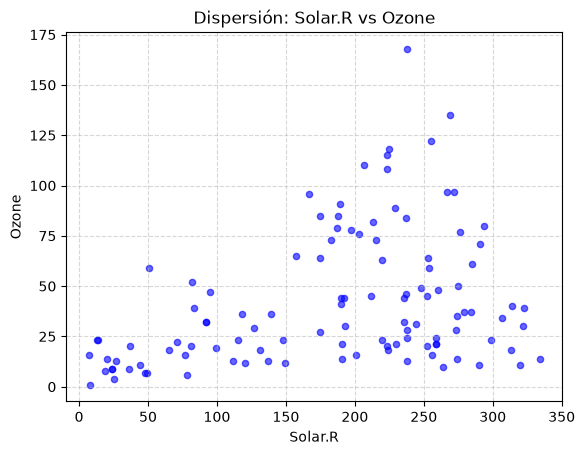

In [23]:
clean_df.plot.scatter(x='Solar.R', y='Ozone', alpha=0.6, color='blue')

# Añadir detalles visuales
plt.title('Dispersión: Solar.R vs Ozone')
plt.xlabel('Solar.R')
plt.ylabel('Ozone')
plt.grid(True, linestyle='--', alpha=0.5)

# Renderizar
plt.show()

En el scatterPlot de arriba podemos ver cierta tendencia lineal entre la variable Solar.R y Ozone

Hay que recordar las ecuaciones estudiadas durante el tema de regresión Lineal, que a continuación son:
- $\beta_0 = \bar{y} - \hat{\beta_{1}}\bar{x}$
- $\beta_{1} = \frac{S_{xy}}{S_{xx}} = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2}$
- $\hat{\sigma}^2 = \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{n - 2}$

In [25]:
# recordar que Y = df["Ozone"] y x = df["Solar.R"]
# Media muestral de X e Y
x_barra = np.mean(clean_df["Solar.R"])
y_barra = np.mean(clean_df["Ozone"])

# Cálculo de Sxy y Sxx
sxy = sum((clean_df["Solar.R"] - x_barra)*(clean_df["Ozone"] - y_barra))
sxx = sum((clean_df["Solar.R"] - x_barra)**2)

# Estimadores
beta_1 = sxy/sxx
beta_0 = y_barra - beta_1*x_barra

print(f"Promedio de X: {x_barra}")
print(f"Promedio de Y: {y_barra}")
print("=========================")
print("Cálculos de Sxy e Sxx")
print(f"Sxy: {sxy}")
print(f"Sxx: {sxx}")
print("=========================")
print("Estimadores de beta 0 y beta 1")
print(f"beta 0: {beta_0}")
print(f"beta 1: {beta_1}")

Promedio de X: 184.80180180180182
Promedio de Y: 42.0990990990991
Cálculos de Sxy e Sxx
Sxy: 116224.18018018018
Sxx: 913961.6396396396
Estimadores de beta 0 y beta 1
beta 0: 18.598727772023313
beta 1: 0.12716527164751193


Para obtener la varianza necesitamos calcular la siguiente suma de los residuos al cuadrado:

$$ \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 $$

> **Nota:** Recordemos las siguientes equivalencias con nuestro código:
> * $y_i$: Observaciones reales de la variable dependiente almacenadas en la columna `clean_df["Ozone"]`.
> * $\hat{y}_i = \hat{\beta}_0 + \hat{\beta}_1 x_i$: Valores estimados por el modelo.
> * $x_i$: Observaciones reales de la variable independiente almacenadas en la columna `clean_df["Solar.R"]`.

En la celda de abajo mostramos el cálculo de $\hat{y_{i}}$

In [27]:
clean_df["Ozone_estimanda"] = beta_0 + beta_1 * clean_df['Solar.R']

In [28]:
clean_df

,Ozone,Solar.R,Wind,Temp,Month,Day,Ozone_estimanda
0,41.0,190.0,7.4,67,5,1,42.760129
1,36.0,118.0,8.0,72,5,2,33.604230
2,12.0,149.0,12.6,74,5,3,37.546353
3,18.0,313.0,11.5,62,5,4,58.401458
6,23.0,299.0,8.6,65,5,7,56.621144
...,...,...,...,...,...,...,...
147,14.0,20.0,16.6,63,9,25,21.142033
148,30.0,193.0,6.9,70,9,26,43.141625
150,14.0,191.0,14.3,75,9,28,42.887295
151,18.0,131.0,8.0,76,9,29,35.257378


In [41]:
n = clean_df.shape[0]
suma_ei_2 = sum((clean_df.Ozone - clean_df.Ozone_estimanda)**2)
sigma2 = suma_ei_2/(n - 2)
print(f"El valor de la varianza es: {sigma2}")

El valor de la varianza es: 981.855325369614


Por lo tanto las estimaciones para mi modelos son $$\beta_0 = 18.598727772023313 $$ $$\beta_1 = 0.12716527164751193 $$ $$\sigma^2 =  981.855325369614$$

### 2. Valores ajustados
**Instrucción:** Muestra cuales son los valores ajustados, es decir, $\hat{y}$.

In [35]:
clean_df["Ozone_estimanda"]

0      42.760129
1      33.604230
2      37.546353
3      58.401458
6      56.621144
         ...    
147    21.142033
148    43.141625
150    42.887295
151    35.257378
152    46.956583
Name: Ozone_estimanda, Length: 111, dtype: float64

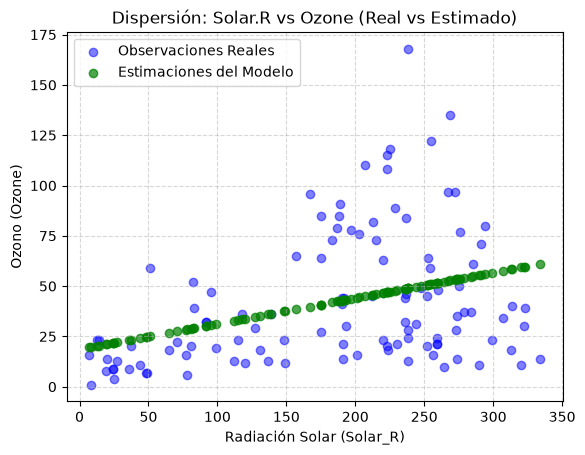

In [38]:
# 1. Graficar las observaciones reales (Datos empíricos)
plt.scatter(clean_df['Solar.R'], clean_df['Ozone'], 
            color='blue', alpha=0.5, label='Observaciones Reales')

# 2. Graficar las estimaciones (Predicciones del modelo)
plt.scatter(clean_df['Solar.R'], clean_df['Ozone_estimanda'], 
            color='green', alpha=0.7, label='Estimaciones del Modelo')

# 3. Añadir detalles visuales
plt.title('Dispersión: Solar.R vs Ozone (Real vs Estimado)')
plt.xlabel('Radiación Solar (Solar_R)')
plt.ylabel('Ozono (Ozone)')
plt.grid(True, linestyle='--', alpha=0.5)

# 4. Activar la leyenda para identificar los colores
plt.legend(loc='best')

# 5. Renderizar
plt.show()

### 3. Suma de residuales
**Instrucción:** Muestra que la suma de residuales es 0, es decir, $\sum_{i=1}^{n} e_i = 0$.

In [43]:
suma_ei = sum(clean_df.Ozone - clean_df.Ozone_estimanda)
print(f"La suma de los residuales es: {suma_ei}")

La suma de los residuales es: 1.2789769243681803e-13


La suma de los residuales es $1.2789769243681803e-13$ que se aproxima demasiado a $0$

### 4. Varianzas de los estimadores
**Instrucción:** Calcula las varianzas de los estimadores de $\beta_0$, $\beta_1$.

Recordemos las ecuaciones de la varianza para nuestros estimadores, los cuales son:
- $Var(\hat{\beta}_0) = \left( \frac{1}{n} + \frac{\bar{X}^2}{S_{xx}} \right) \sigma^2$

- $Var(\hat{\beta}_1) = \frac{1}{S_{xx}} \sigma^2$

In [47]:
n = clean_df.shape[0]
var_b0 = (1/n + x_barra**2/sxx)*sigma2
var_b1 = sigma2/sxx

print(f"La varianza del estimador beta 0 es: {var_b0}")
print(f"La varianza del estimador beta 1 es: {var_b1}")

La varianza del estimador beta 0 es: 45.5342105912333
La varianza del estimador beta 1 es: 0.0010742850495965494


### 5. Propiedades algebraicas
**Instrucción:** Con los resultados obtenidos muestra que con los datos recabados se cumple:
1. a) $\sum_{i=1}^{n} (x_i - \bar{x})^2 = \sum_{i=1}^{n} (x_i - \bar{x})x_i = \sum_{i=1}^{n} (x_i^2) - n\bar{x}^2$
2. b) $\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y}) = \sum_{i=1}^{n} (x_i - \bar{x})y_i = \sum_{i=1}^{n} (y_i - \bar{y})x_i = \sum_{i=1}^{n} (x_i y_i) - n\bar{x}\bar{y}$
3. c) $\sum_{i=1}^{n} x_i e_i = 0$
4. d) $\sum_{i=1}^{n} y_i e_i = \sum e_i^2$

**a)**
Anteriormente ya calculamos `sxx = 913961.6396396396 ` que esta variable guarda la suma $\sum_{i=1}^{n} (x_i - \bar{x})^2$. Veamos que `sxx` es igual a $\sum_{i=1}^{n} (x_i - \bar{x})x_i$ y a  $\sum_{i=1}^{n} (x_i^2) - n\bar{x}^2$.

Empezamos calculando $\sum_{i=1}^{n} (x_i - \bar{x})x_i$ en la celda de abajo:

In [53]:
sum((clean_df["Solar.R"] - x_barra)*clean_df["Solar.R"])

913961.6396396393

Ahora  $\sum_{i=1}^{n} (x_i^2) - n\bar{x}^2$ en la celda de abajo:

In [55]:
sum(clean_df["Solar.R"]**2) - (n * (x_barra**2))

np.float64(913961.6396396393)

De esta manera obtuvimos que:
$$\sum_{i=1}^{n} (x_i - \bar{x})x_i = 913961.6396396393$$
$$\sum_{i=1}^{n} (x_i^2) - n\bar{x}^2 = 913961.6396396393$$
Por lo tanto se cumple que $\sum_{i=1}^{n} (x_i - \bar{x})^2 = \sum_{i=1}^{n} (x_i - \bar{x})x_i = \sum_{i=1}^{n} (x_i^2) - n\bar{x}^2$

**b)**
Sabemos que $\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})$ se almacena en la variable `sxy = 116224.18018018018`. Nuestro obejtivo es verificar que este valor coincida con $\sum_{i=1}^{n} (x_i - \bar{x})y_i$, $\sum_{i=1}^{n} (y_i - \bar{y})x_i$ y $\sum_{i=1}^{n} (x_i y_i) - n\bar{x}\bar{y}$

Comenzando con $\sum_{i=1}^{n} (x_i - \bar{x})y_i$

In [57]:
sum((clean_df['Solar.R'] - x_barra)*clean_df['Ozone']) # Coincide con sxy

116224.18018018012

Pasamos a $\sum_{i=1}^{n} (y_i - \bar{y})x_i$

In [58]:
sum((clean_df['Ozone'] - y_barra)*clean_df['Solar.R']) # Coincide con sxy

116224.18018018015

Por último tenemos a $\sum_{i=1}^{n} (x_i y_i) - n\bar{x}\bar{y}$

In [59]:
sum(clean_df['Solar.R'] * clean_df['Ozone']) - n * x_barra * y_barra

np.float64(116224.18018018012)

Con los cálculos de arriba podemos concluir que: $$ \sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y}) = \sum_{i=1}^{n} (x_i - \bar{x})y_i = \sum_{i=1}^{n} (y_i - \bar{y})x_i = \sum_{i=1}^{n} (x_i y_i) - n\bar{x}\bar{y}$$

**c)** Validar que $\sum_{i=1}^{n} x_i e_i = 0$

In [61]:
sum(clean_df['Solar.R'] * (clean_df['Ozone'] - clean_df['Ozone_estimanda']))

2.5369928380314377e-11

el valor obtenido sin la notación decimal es: $0.0000000000253699....$. Por lo tanto $\sum_{i=1}^{n} x_i e_i = 0$

**d)** Validar que: $\sum_{i=1}^{n} y_i e_i = \sum e_i^2$. Vamos a trabajar ambas sumas por separado.
Comenzamos con $\sum_{i=1}^{n} y_i e_i$ calculando la suma en python

In [62]:
sum(clean_df['Ozone'] * (clean_df['Ozone'] - clean_df['Ozone_estimanda']))

107022.23046528792

Por otro lado, $\sum e_i^2$ es igual a: 

In [63]:
sum((clean_df['Ozone'] - clean_df['Ozone_estimanda'])**2)

107022.23046528792

Podemos notar que las dos sumas de arriba coinciden por lo tanto, $$\sum_{i=1}^{n} y_i e_i = \sum e_i^2 $$

### 6. Intervalos de confianza
**Instrucción:** Calcula los intervalos de confianza para $\beta_0$, $\beta_1$ y $\sigma^2$.